# Install libraries

In [1]:
pip install pingouin

Note: you may need to restart the kernel to use updated packages.


In [2]:
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

In [3]:
# Core analysis packages
import numpy as np
import pingouin as pg
import os, sys
import pandas as pd
from scipy import stats
from scipy.special import comb
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats import anova
import matplotlib.pyplot as plt

#Plotting packages
import matplotlib.pyplot as plt
plt.rcdefaults()
import seaborn as sns
sns.set(style="ticks", color_codes=True)
sns.set_style("white")
sns.set_style({'xtick.bottom': True, 'ytick.left': True})
colorref = ["gray", "royalblue", "crimson", "goldenrod", "mediumorchid", "seagreen"]

from patsy import dmatrices

# iPython magic commands
%matplotlib inline
%load_ext autoreload
%autoreload 2

SMALL_SIZE = 12
MEDIUM_SIZE = 12
BIG_SIZE = 14

plt.rc('font', size=SMALL_SIZE)          # controls default text sizes
plt.rc('axes', titlesize=SMALL_SIZE)     # fontsize of the axes title
plt.rc('axes', labelsize=MEDIUM_SIZE)    # fontsize of the x and y labels
plt.rc('xtick', labelsize=SMALL_SIZE)    # fontsize of the tick labels
plt.rc('ytick', labelsize=SMALL_SIZE)    # fontsize of the tick labels
plt.rc('legend', fontsize=SMALL_SIZE)    # legend fontsize
plt.rc('figure', titlesize=BIG_SIZE)  # fontsize of the figure title
cust_palette = sns.color_palette("Paired")[6:10]
cust_palette = [cust_palette[i] for i in [1,0,3,2]]

def median_split(S):
    return S > S.median()

# Primary Variables

In [4]:
# Import the voting intentions estimates

int_est = pd.read_csv("Intentions_Percent.csv")

# Sort by descending

int_est = int_est.sort_values(by=['Mean'], ascending=False)
int_est

,Condition,Mean,Lower_ci,Upper_ci
4,EscalatingCommitment,32.537313,30.921520,34.153107
2,DistrustSalience,30.965488,29.428956,32.502021
10,SystemJustification,30.611702,29.043358,32.180047
8,PersonalImportance,30.457895,28.913927,32.001862
3,DynamicNorms,29.273424,27.741102,30.805746
7,MoralReasons,29.197861,27.674882,30.720840
5,ImplementationIntentions,27.756877,26.236875,29.276878
6,InterdependentConstrual,27.082305,25.602306,28.562303
1,CorrectingMisperceptions,27.065915,25.606642,28.525188
9,SelfGeneratedNorms,26.176161,24.682923,27.669399


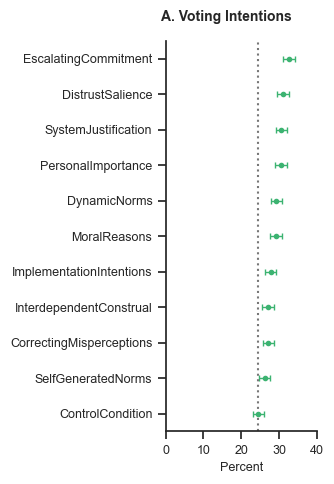

In [6]:
# Point plot intentions

pal = ["mediumseagreen"]

# Point plot (for manuscript)

fig, ax = plt.subplots(figsize=(3.5, 5))

sns.pointplot(
    data=int_est,
    y="Condition",
    x="Mean",
    orient="h",
    color="mediumseagreen",
    linestyle="none",   # replaces join=False
    errorbar=None,      # prevents seaborn CI bars
    markers="o",
    markersize=2,
    zorder=3,
    ax=ax
)

# Add custom error bars
ax.errorbar(
    x=int_est["Mean"],
    y=np.arange(len(int_est)),
    xerr=[
        int_est["Mean"] - int_est["Lower_ci"],
        int_est["Upper_ci"] - int_est["Mean"]
    ],
    fmt='none',
    capsize=2,
    elinewidth=1,
    color='mediumseagreen',
    zorder=2
)

# Labels
ax.set_xlabel("Percent", fontsize=9)
ax.set_ylabel("")

# Title
ax.set_title(
    "A. Voting Intentions",
    fontweight='bold',
    y=1.03,
    x=.40,
    fontsize=10
)

# Tick sizes
ax.tick_params(axis='x', labelsize=9)
ax.tick_params(axis='y', labelsize=9)

# X-axis limits
ax.set_xlim(0, 40)
ax.set_xticks(np.arange(0, 41, 10))

# Remove grids
ax.xaxis.grid(False)
ax.yaxis.grid(False)

# Remove top/right borders
sns.despine()

# Vertical line at control condition mean
control_mean = int_est.loc[
    int_est["Condition"] == "ControlCondition",
    "Mean"
].values[0]

ax.axvline(
    x=control_mean,
    color="#777777",
    linestyle=":"
)

plt.tight_layout()

# plt.savefig('1A_Fig_Intentions_Normal.pdf', dpi=300, bbox_inches='tight')

plt.show()


In [7]:
# Import the link clicks (raw percentage points)

link_est = pd.read_csv("Link_Percent.csv")
link_est

# Sort by descending

link_est = link_est.sort_values(by=['Mean'], ascending=False)
link_est

,Condition,Mean,Lower_ci,Upper_ci
4,EscalatingCommitment,3.767123,2.849899,4.684348
10,SystemJustification,3.394256,2.514727,4.273785
3,DynamicNorms,3.164030,2.332482,3.995578
1,CorrectingMisperceptions,3.135593,2.300322,3.970865
5,ImplementationIntentions,3.051439,2.215300,3.887578
8,PersonalImportance,2.751505,1.961793,3.541217
2,DistrustSalience,2.664446,1.899400,3.429493
6,InterdependentConstrual,2.591093,1.846845,3.335341
7,MoralReasons,2.094241,1.397835,2.790647
0,ControlCondition,1.629503,1.019064,2.239941


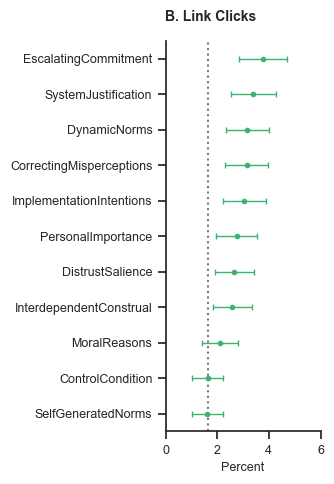

In [10]:
# Point plot link clicks

fig, ax = plt.subplots(figsize=(3.5, 5))

sns.pointplot(
    data=link_est,
    y="Condition",
    x="Mean",
    orient="h",
    color="mediumseagreen",
    linestyle="none",
    errorbar=None,
    markers="o",
    markersize=2,
    zorder=3,
    ax=ax
)

# Add custom error bars
ax.errorbar(
    x=link_est["Mean"],
    y=np.arange(len(link_est)),
    xerr=[
        link_est["Mean"] - link_est["Lower_ci"],
        link_est["Upper_ci"] - link_est["Mean"]
    ],
    fmt='none',
    capsize=2,
    elinewidth=1,
    color='mediumseagreen',
    zorder=2
)

# Labels
ax.set_xlabel("Percent", fontsize=9)
ax.set_ylabel("")

# Title
ax.set_title(
    "B. Link Clicks",
    fontweight='bold',
    y=1.03,
    x=.29,
    fontsize=10
)

# Tick sizes
ax.tick_params(axis='x', labelsize=9)
ax.tick_params(axis='y', labelsize=9)

# X-axis limits
ax.set_xlim(0, 6)

# Remove grids
ax.xaxis.grid(False)
ax.yaxis.grid(False)

# Remove top/right borders
sns.despine()

# Vertical line at control condition mean
control_mean = link_est.loc[
    link_est["Condition"] == "ControlCondition",
    "Mean"
].values[0]

ax.axvline(
    x=control_mean,
    color="#777777",
    linestyle=":"
)

plt.tight_layout()

# plt.savefig('1B_Fig_LinkClicks_Normal.pdf', dpi=300, format="pdf", bbox_inches='tight')

plt.show()

In [11]:
# Import the registration estimates

reg_est = pd.read_csv("Register_Percent.csv")

# Sort by descending

reg_est = reg_est.sort_values(by=['Mean'], ascending=False)
reg_est

,Condition,Mean,Lower_ci,Upper_ci
9,SelfGeneratedNorms,3.501281,2.616929,4.385633
0,ControlCondition,3.259005,2.402895,4.115115
4,EscalatingCommitment,3.082192,2.249584,3.914800
3,DynamicNorms,3.080766,2.259880,3.901652
10,SystemJustification,3.046127,2.211422,3.880832
5,ImplementationIntentions,2.964255,2.139776,3.788733
8,PersonalImportance,2.837489,2.035888,3.639091
6,InterdependentConstrual,2.834008,2.056626,3.611390
1,CorrectingMisperceptions,2.627119,1.860562,3.393676
7,MoralReasons,2.617801,1.841280,3.394322


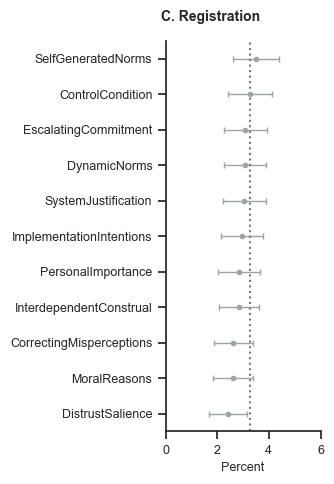

In [19]:
# Point plot registration

fig, ax = plt.subplots(figsize=(3.5, 5))

sns.pointplot(
    data=reg_est,
    y="Condition",
    x="Mean",
    orient="h",
    color="#9EA3A3",
    linestyle="none",
    errorbar=None,
    markers="o",
    markersize=2,
    zorder=3,
    ax=ax
)

# Add custom error bars
ax.errorbar(
    x=reg_est["Mean"],
    y=np.arange(len(reg_est)),
    xerr=[
        reg_est["Mean"] - reg_est["Lower_ci"],
        reg_est["Upper_ci"] - reg_est["Mean"]
    ],
    fmt='none',
    capsize=2,
    elinewidth=1,
    color="#9EA3A3",
    zorder=2
)

# Labels
ax.set_xlabel("Percent", fontsize=9)
ax.set_ylabel("")

# Title
ax.set_title(
    "C. Registration",
    fontweight='bold',
    y=1.03,
    x=.29,
    fontsize=10
)

# Tick sizes
ax.tick_params(axis='x', labelsize=9)
ax.tick_params(axis='y', labelsize=9)

# X-axis limits
ax.set_xlim(0, 6)

# Remove grids
ax.xaxis.grid(False)
ax.yaxis.grid(False)

# Remove top/right borders
sns.despine()

# Vertical line at control condition mean
control_mean = reg_est.loc[
    reg_est["Condition"] == "ControlCondition",
    "Mean"
].values[0]

ax.axvline(
    x=control_mean,
    color="#777777",
    linestyle=":"
)

plt.tight_layout()

# plt.savefig('1C_Fig_Reg_Normal.pdf', dpi=300, format="pdf", bbox_inches='tight')

plt.show()

In [20]:
# Import the voting estimates

vote_est = pd.read_csv("Vote_Percent.csv")

# Sort by descending

vote_est = vote_est.sort_values(by=['Mean'], ascending=False)
vote_est

,Condition,Mean,Lower_ci,Upper_ci
3,DynamicNorms,1.582015,0.989238,2.174792
8,PersonalImportance,1.289768,0.745041,1.834495
0,ControlCondition,1.286449,0.743116,1.829783
1,CorrectingMisperceptions,1.271186,0.734263,1.808110
5,ImplementationIntentions,1.220575,0.686785,1.754366
4,EscalatingCommitment,1.113014,0.607621,1.618406
9,SelfGeneratedNorms,1.024765,0.540229,1.509302
2,DistrustSalience,0.999167,0.526683,1.471651
10,SystemJustification,0.783290,0.355106,1.211474
6,InterdependentConstrual,0.728745,0.330293,1.127197


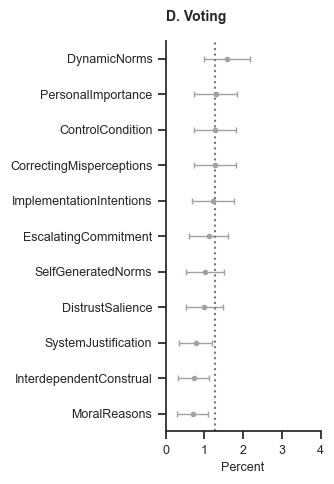

In [25]:
# Point plot voting

fig, ax = plt.subplots(figsize=(3.5, 5))

sns.pointplot(
    data=vote_est,
    y="Condition",
    x="Mean",
    orient="h",
    color="#9EA3A3",
    linestyle="none",
    errorbar=None,
    markers="o",
    markersize=2,
    zorder=3,
    ax=ax
)

# Add custom error bars
ax.errorbar(
    x=vote_est["Mean"],
    y=np.arange(len(vote_est)),
    xerr=[
        vote_est["Mean"] - vote_est["Lower_ci"],
        vote_est["Upper_ci"] - vote_est["Mean"]
    ],
    fmt='none',
    capsize=2,
    elinewidth=1,
    color="#9EA3A3",
    zorder=2
)

# Labels
ax.set_xlabel("Percent", fontsize=9)
ax.set_ylabel("")

# Title
ax.set_title(
    "D. Voting",
    fontweight='bold',
    y=1.03,
    x=.20,
    fontsize=10
)

# Tick sizes
ax.tick_params(axis='x', labelsize=9)
ax.tick_params(axis='y', labelsize=9)

# X-axis limits
ax.set_xlim(0, 4)

# Remove grids
ax.xaxis.grid(False)
ax.yaxis.grid(False)

# Remove top/right borders
sns.despine()

# Vertical line at control condition mean
control_mean = vote_est.loc[
    vote_est["Condition"] == "ControlCondition",
    "Mean"
].values[0]

ax.axvline(
    x=control_mean,
    color="#777777",
    linestyle=":"
)

plt.tight_layout()

# plt.savefig('Fig_Voting_Normal.pdf', dpi=300, format="pdf", bbox_inches='tight')

plt.show()


# Additional Psych Variables

In [26]:
# Import the trust estimates

trust_est = pd.read_csv("Trust_Percent.csv")

# Sort by descending

trust_est = trust_est.sort_values(by=['Mean'], ascending=False)
trust_est

,Condition,Mean,Lower_ci,Upper_ci
4,EscalatingCommitment,35.858848,34.300764,37.416931
10,SystemJustification,35.593467,34.038549,37.148386
3,DynamicNorms,35.416109,33.882299,36.949920
5,ImplementationIntentions,34.941696,33.437502,36.445890
8,PersonalImportance,34.923437,33.440796,36.406078
7,MoralReasons,34.690143,33.178383,36.201903
2,DistrustSalience,34.634406,33.149613,36.119200
1,CorrectingMisperceptions,33.799673,32.306166,35.293179
9,SelfGeneratedNorms,32.341195,30.826090,33.856300
6,InterdependentConstrual,32.194512,30.751562,33.637462


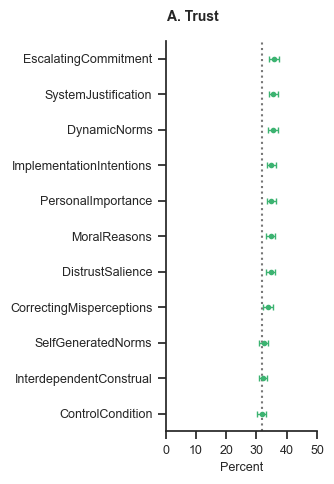

In [29]:
# Point plot trust

fig, ax = plt.subplots(figsize=(3.5, 5))

sns.pointplot(
    data=trust_est,
    y="Condition",
    x="Mean",
    orient="h",
    color="mediumseagreen",
    linestyle="none",
    errorbar=None,
    markers="o",
    markersize=2,
    zorder=3,
    ax=ax
)

# Add custom error bars
ax.errorbar(
    x=trust_est["Mean"],
    y=np.arange(len(trust_est)),
    xerr=[
        trust_est["Mean"] - trust_est["Lower_ci"],
        trust_est["Upper_ci"] - trust_est["Mean"]
    ],
    fmt='none',
    capsize=2,
    elinewidth=1,
    color="mediumseagreen",
    zorder=2
)

# Labels
ax.set_xlabel("Percent", fontsize=9)
ax.set_ylabel("")

# Title
ax.set_title(
    "A. Trust",
    fontweight='bold',
    y=1.03,
    x=.18,
    fontsize=10
)

# Tick sizes
ax.tick_params(axis='x', labelsize=9)
ax.tick_params(axis='y', labelsize=9)

# X-axis limits
ax.set_xlim(0, 50)
ax.set_xticks(np.arange(0, 51, 10))

# Remove grids
ax.xaxis.grid(False)
ax.yaxis.grid(False)

# Remove top/right borders
sns.despine()

# Vertical line at control condition mean
control_mean = trust_est.loc[
    trust_est["Condition"] == "ControlCondition",
    "Mean"
].values[0]

ax.axvline(
    x=control_mean,
    color="#777777",
    linestyle=":"
)

plt.tight_layout()

# plt.savefig('2A_Fig_Trust_Normal.pdf', dpi=300, bbox_inches='tight')

plt.show()

In [30]:
# Import the efficacy estimates

efficacy_est = pd.read_csv("Efficacy_Percent.csv")

# Sort by descending

efficacy_est = efficacy_est.sort_values(by=['Mean'], ascending=False)
efficacy_est

,Condition,Mean,Lower_ci,Upper_ci
4,EscalatingCommitment,42.031501,40.201090,43.861911
2,DistrustSalience,39.736041,37.959671,41.512411
7,MoralReasons,39.728584,37.914294,41.542874
8,PersonalImportance,39.303736,37.553853,41.053618
3,DynamicNorms,39.283682,37.515291,41.052073
10,SystemJustification,39.278069,37.442023,41.114114
5,ImplementationIntentions,38.018664,36.273782,39.763546
9,SelfGeneratedNorms,36.996420,35.232385,38.760456
1,CorrectingMisperceptions,36.874573,35.154684,38.594463
6,InterdependentConstrual,36.166802,34.448375,37.885228


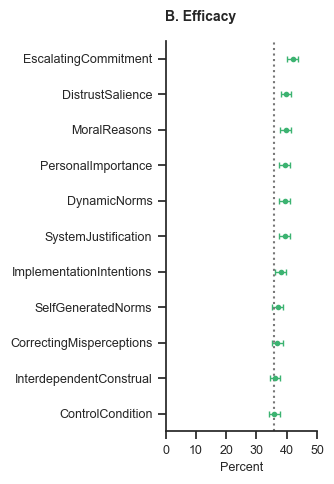

In [32]:
# Point plot efficacy

fig, ax = plt.subplots(figsize=(3.5, 5))

sns.pointplot(
    data=efficacy_est,
    y="Condition",
    x="Mean",
    orient="h",
    color="mediumseagreen",
    linestyle="none",
    errorbar=None,
    markers="o",
    markersize=2,
    zorder=3,
    ax=ax
)

# Add custom error bars
ax.errorbar(
    x=efficacy_est["Mean"],
    y=np.arange(len(efficacy_est)),
    xerr=[
        efficacy_est["Mean"] - efficacy_est["Lower_ci"],
        efficacy_est["Upper_ci"] - efficacy_est["Mean"]
    ],
    fmt='none',
    capsize=2,
    elinewidth=1,
    color="mediumseagreen",
    zorder=2
)

# Labels
ax.set_xlabel("Percent", fontsize=9)
ax.set_ylabel("")

# Title
ax.set_title(
    "B. Efficacy",
    fontweight='bold',
    y=1.03,
    x=.23,
    fontsize=10
)

# Tick sizes
ax.tick_params(axis='x', labelsize=9)
ax.tick_params(axis='y', labelsize=9)

# X-axis limits
ax.set_xlim(0, 50)
ax.set_xticks(np.arange(0, 51, 10))

# Remove grids
ax.xaxis.grid(False)
ax.yaxis.grid(False)

# Remove top/right borders
sns.despine()

# Vertical line at control condition mean
control_mean = efficacy_est.loc[
    efficacy_est["Condition"] == "ControlCondition",
    "Mean"
].values[0]

ax.axvline(
    x=control_mean,
    color="#777777",
    linestyle=":"
)

plt.tight_layout()

# plt.savefig('2B_Fig_Efficacy_Normal.pdf', dpi=300, bbox_inches='tight')

plt.show()

In [33]:
# Import the norms estimates

norms_est = pd.read_csv("Norms_Percent.csv")

# Sort by descending

norms_est = norms_est.sort_values(by=['Mean'], ascending=False)
norms_est

,Condition,Mean,Lower_ci,Upper_ci
2,DistrustSalience,50.149541,48.371455,51.927626
4,EscalatingCommitment,49.805675,48.051996,51.559354
3,DynamicNorms,49.431970,47.650229,51.213711
10,SystemJustification,48.917539,47.085776,50.749303
5,ImplementationIntentions,48.896144,47.161980,50.630307
7,MoralReasons,48.351269,46.534695,50.167842
8,PersonalImportance,48.238116,46.437407,50.038824
1,CorrectingMisperceptions,47.725214,45.974240,49.476187
6,InterdependentConstrual,47.585089,45.820153,49.350025
0,ControlCondition,47.382455,45.558222,49.206687


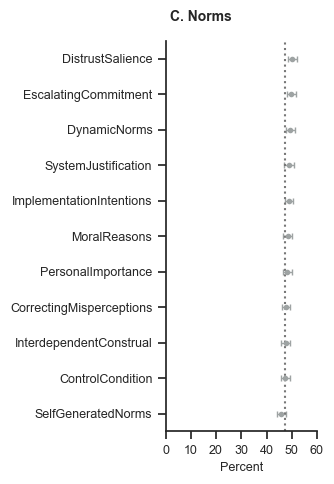

In [35]:
# Point plot norms

fig, ax = plt.subplots(figsize=(3.5, 5))

sns.pointplot(
    data=norms_est,
    y="Condition",
    x="Mean",
    orient="h",
    color="#9EA3A3",
    linestyle="none",
    errorbar=None,
    markers="o",
    markersize=2,
    zorder=3,
    ax=ax
)

# Add custom error bars
ax.errorbar(
    x=norms_est["Mean"],
    y=np.arange(len(norms_est)),
    xerr=[
        norms_est["Mean"] - norms_est["Lower_ci"],
        norms_est["Upper_ci"] - norms_est["Mean"]
    ],
    fmt='none',
    capsize=2,
    elinewidth=1,
    color="#9EA3A3",
    zorder=2
)

# Labels
ax.set_xlabel("Percent", fontsize=9)
ax.set_ylabel("")

# Title
ax.set_title(
    "C. Norms",
    fontweight='bold',
    y=1.03,
    x=.23,
    fontsize=10
)

# Tick sizes
ax.tick_params(axis='x', labelsize=9)
ax.tick_params(axis='y', labelsize=9)

# X-axis limits
ax.set_xlim(0, 60)
ax.set_xticks(np.arange(0, 61, 10))

# Remove grids
ax.xaxis.grid(False)
ax.yaxis.grid(False)

# Remove top/right borders
sns.despine()

# Vertical line at control condition mean
control_mean = norms_est.loc[
    norms_est["Condition"] == "ControlCondition",
    "Mean"
].values[0]

ax.axvline(
    x=control_mean,
    color="#777777",
    linestyle=":"
)

plt.tight_layout()

# plt.savefig('2C_Fig_Norms_Normal.pdf', dpi=300, bbox_inches='tight')

plt.show()

# Intervention Rankings

In [52]:
# Import intervention rankings from advsiors 

rankings = pd.read_csv("Voter_Reg_Rankings.csv")
rankings

# Remove top row with longer intervention names
rankings = rankings.drop(0)
rankings


,Response_ID,Name,SelfGeneratedNorms,Gratitude,CorrectingMisperceptions,Gamification,SystemJustification,EqualityAppeal,ImplementationIntentions,PoeticEngagement,...,VotingBenefits,FearFrame,PersonalLegacy,DynamicNorms,LetterFutureGen,EscalatingCommitment,Nostalgia,DescriptiveRepresentation,DistrustSalience,NationalIdentity
1,R_5PTcwTwgPQUoURm,Jamie Druckman,7,22,24,5,4,3,2,29,...,18,15,30,11,27,10,31,26,19,25
2,R_7FRQVZmWdGMEFCb,Madalina Vlasceanu,13,18,3,10,4,5,2,31,...,22,20,27,7,1,16,23,26,28,9
3,R_1pPvnUJV6weLmEH,Robb Willer,17,28,20,6,25,26,8,30,...,14,5,9,13,15,1,19,24,11,4
4,R_69iqSvNu31Euwk9,Matthew Schneider-Mayerson,11,12,9,6,24,23,31,29,...,15,19,30,8,2,7,28,22,13,20
5,R_7FmJy3fRKGwqUJe,Don Green,11,21,4,20,19,29,12,13,...,27,25,16,26,17,8,18,31,9,10
6,R_7j6xgpGOv0EwjlX,Erika Weisz,10,27,5,20,22,28,18,31,...,17,16,24,11,12,2,30,21,15,29
7,R_6J2DWeDcL44WpTH,Sara Constantino,3,14,1,30,5,21,26,31,...,12,10,17,25,28,4,24,20,18,19
8,R_7lQxp4gp6rl1dne,Danielle Goldwert,7,29,1,25,13,16,22,30,...,14,9,24,3,15,5,20,19,18,4
9,R_7faRxrkyGNr3YzL,Katie Mason,24,15,10,21,2,1,8,19,...,20,26,23,3,7,30,22,9,18,14
10,R_1gGPvK50Z0dcYQx,Todd Rogers,13,19,18,6,23,30,5,2,...,26,10,21,20,27,17,16,29,11,31


In [41]:
# Make ranking data long

rankings_long = pd.melt(rankings, id_vars=['Response_ID'], 
                        value_vars=['SelfGeneratedNorms', 'Gratitude', 'CorrectingMisperceptions', 
                                    'Gamification', 'SystemJustification', 'EqualityAppeal', 
                                    'ImplementationIntentions', 'PoeticEngagement', 'InterdependentConstrual', 
                                    'VotingAdvice', 'PersonalImportance.A', 'Reactance', 'OpponentsMobilizing', 
                                    'MoralReasons', 'PracticalReasons', 'RejectionFrame', 'RecordsPublic', 'HeavyHitter', 
                                    'PersonalImportance.B', 'ForerEffect', 'Urgency', 'VotingBenefits', 
                                    'FearFrame', 'PersonalLegacy', 'DynamicNorms', 'LetterFutureGen', 
                                    'EscalatingCommitment', 'Nostalgia', 'DescriptiveRepresentation', 
                                    'DistrustSalience', 'NationalIdentity'],
                        var_name='Intervention', value_name='Rating')

rankings_long

# Make sure ratings are numeric
rankings_long['Rating'] = rankings_long['Rating'].astype(int)

# Reverse score rank

# Number of interventions 
k = rankings_long['Intervention'].nunique()

# Reverse-score so higher = better (N + 1 - rank)
rankings_long['RevRank'] = (k + 1) - rankings_long['Rating']

rankings_long

,Response_ID,Intervention,Rating,RevRank
0,R_5PTcwTwgPQUoURm,SelfGeneratedNorms,7,25
1,R_7FRQVZmWdGMEFCb,SelfGeneratedNorms,13,19
2,R_1pPvnUJV6weLmEH,SelfGeneratedNorms,17,15
3,R_69iqSvNu31Euwk9,SelfGeneratedNorms,11,21
4,R_7FmJy3fRKGwqUJe,SelfGeneratedNorms,11,21
...,...,...,...,...
336,R_6J2DWeDcL44WpTH,NationalIdentity,19,13
337,R_7lQxp4gp6rl1dne,NationalIdentity,4,28
338,R_7faRxrkyGNr3YzL,NationalIdentity,14,18
339,R_1gGPvK50Z0dcYQx,NationalIdentity,31,1


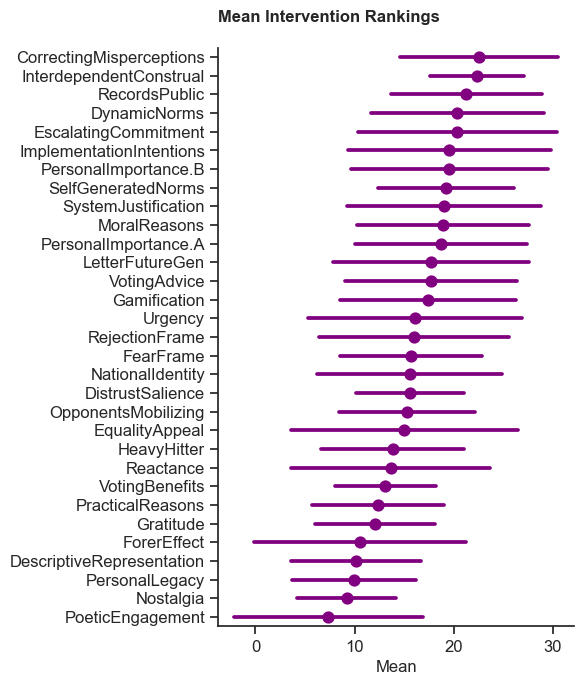

In [51]:
# Plot intervention rankings

fig, ax = plt.subplots(1, 1, figsize=(6, 7))

order = (
    rankings_long.groupby("Intervention")["RevRank"]
    .mean()
    .sort_values(ascending=False)
    .index
)

sns.pointplot(
    data=rankings_long,
    y="Intervention",
    x="RevRank",
    errorbar=("ci", 95),
    # errorbar="sd",
    color="purple",
    linestyle="none",
    order=order,
    ax=ax
)

sns.despine()

ax.set_ylabel("")
ax.set_xlabel("Mean")
plt.title("Mean Intervention Rankings",
          fontweight="bold", y=1.03, x=.31, fontsize=12)

plt.tight_layout()

# plt.savefig('InterventionRatings.pdf', dpi=900, format="pdf")